# Goodreads Best Books Ever – Veri Seti Keşif Analizi

In [17]:
from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATASET_PATH = (
    PROJECT_ROOT
    / "data"
    / "metadata"
    / "books_1.Best_Books_Ever.csv"
)

goodreads_df = pd.read_csv(
    DATASET_PATH,
    low_memory=False
)

print("Veri seti boyutu:", goodreads_df.shape)

print("\nSütun isimleri:")
print(goodreads_df.columns.tolist())

print("\nİlk 5 kitap:")
display(
    goodreads_df[
        ["bookId", "title", "genres", "coverImg"]
    ].head()
)

Veri seti boyutu: (52478, 25)

Sütun isimleri:
['bookId', 'title', 'series', 'author', 'rating', 'description', 'language', 'isbn', 'genres', 'characters', 'bookFormat', 'edition', 'pages', 'publisher', 'publishDate', 'firstPublishDate', 'awards', 'numRatings', 'ratingsByStars', 'likedPercent', 'setting', 'coverImg', 'bbeScore', 'bbeVotes', 'price']

İlk 5 kitap:


,bookId,title,genres,coverImg
0,2767052-the-hunger-games,The Hunger Games,"['Young Adult', 'Fiction', 'Dystopia', 'Fantas...",https://i.gr-assets.com/images/S/compressed.ph...
1,2.Harry_Potter_and_the_Order_of_the_Phoenix,Harry Potter and the Order of the Phoenix,"['Fantasy', 'Young Adult', 'Fiction', 'Magic',...",https://i.gr-assets.com/images/S/compressed.ph...
2,2657.To_Kill_a_Mockingbird,To Kill a Mockingbird,"['Classics', 'Fiction', 'Historical Fiction', ...",https://i.gr-assets.com/images/S/compressed.ph...
3,1885.Pride_and_Prejudice,Pride and Prejudice,"['Classics', 'Fiction', 'Romance', 'Historical...",https://i.gr-assets.com/images/S/compressed.ph...
4,41865.Twilight,Twilight,"['Young Adult', 'Fantasy', 'Romance', 'Vampire...",https://i.gr-assets.com/images/S/compressed.ph...


In [18]:
# Bütün sütunlardaki eksik değer sayıları
missing_values = goodreads_df.isna().sum()

missing_percent = (
    missing_values / len(goodreads_df) * 100
).round(2)

missing_analysis = pd.DataFrame({
    "Eksik Sayısı": missing_values,
    "Eksik Yüzdesi": missing_percent
})

display(missing_analysis)

print("\nToplam kayıt:", len(goodreads_df))

print(
    "Tür bilgisi bulunan:",
    goodreads_df["genres"].notna().sum()
)

print(
    "Kapak URL'si bulunan:",
    goodreads_df["coverImg"].notna().sum()
)

print(
    "Hem tür hem kapak URL'si bulunan:",
    goodreads_df[
        ["genres", "coverImg"]
    ].notna().all(axis=1).sum()
)

print(
    "Tekrarlanan kitap kimliği:",
    goodreads_df["bookId"].duplicated().sum()
)

,Eksik Sayısı,Eksik Yüzdesi
bookId,0,0.00
title,0,0.00
series,29008,55.28
author,0,0.00
rating,0,0.00
description,1338,2.55
language,3806,7.25
isbn,0,0.00
genres,0,0.00
characters,0,0.00



Toplam kayıt: 52478
Tür bilgisi bulunan: 52478
Kapak URL'si bulunan: 51873
Hem tür hem kapak URL'si bulunan: 51873
Tekrarlanan kitap kimliği: 54


In [19]:
import ast
from collections import Counter

def parse_genres(value):
    if pd.isna(value):
        return []

    try:
        genres = ast.literal_eval(value)

        if isinstance(genres, list):
            return genres

    except (ValueError, SyntaxError, TypeError):
        pass

    return []

goodreads_df["genre_list"] = (
    goodreads_df["genres"].apply(parse_genres)
)

genre_counts = Counter(
    genre
    for genres in goodreads_df["genre_list"]
    for genre in genres
)

print("Benzersiz tür sayısı:", len(genre_counts))

print("\nEn yaygın 20 tür:")

for genre, count in genre_counts.most_common(20):
    print(f"{genre}: {count}")

Benzersiz tür sayısı: 982

En yaygın 20 tür:
Fiction: 31638
Romance: 15495
Fantasy: 15046
Young Adult: 11869
Contemporary: 10520
Nonfiction: 8251
Adult: 8246
Novels: 7805
Mystery: 7702
Historical Fiction: 7665
Audiobook: 7307
Classics: 6902
Adventure: 6452
Historical: 6383
Paranormal: 6030
Literature: 5836
Science Fiction: 5374
Childrens: 5226
Thriller: 4587
Magic: 4248


## Tür ve Kapak URL Kalite Kontrolleri / Genre and Cover URL Quality Checks

In [20]:
# Tür listelerinin kullanılabilirliğini kontrol et
empty_genres = goodreads_df["genre_list"].apply(
    lambda genres: len(genres) == 0
).sum()

# Geçerli URL biçimini kontrol et
valid_url = (
    goodreads_df["coverImg"]
    .fillna("")
    .str.startswith(("http://", "https://"))
)

# Hem tür hem URL koşulunu sağlayan kayıtlar
usable_records = (
    (goodreads_df["genre_list"].apply(len) > 0)
    & valid_url
)

print("Boş veya ayrıştırılamayan tür listesi:", empty_genres)
print("URL biçimi geçerli kayıt:", valid_url.sum())
print("Tür listesi ve URL koşulunu sağlayan:", usable_records.sum())

# Tekrarlanan kitap kimliklerini incele
print("\nTekrarlanan kimliklere ait örnek kayıtlar:")

display(
    goodreads_df[
        goodreads_df["bookId"].duplicated(keep=False)
    ][["bookId", "title", "genres"]].head(10)
)

Boş veya ayrıştırılamayan tür listesi: 4623
URL biçimi geçerli kayıt: 51873
Tür listesi ve URL koşulunu sağlayan: 47571

Tekrarlanan kimliklere ait örnek kayıtlar:


,bookId,title,genres
37377,8794263-promises-to-keep,Promises to Keep,"['Fiction', 'Christian Fiction', 'Christian', ..."
37378,1909590.Click,Click,"['Young Adult', 'Fiction', 'Short Stories', 'M..."
37379,23394408-die-unendlichkeit-schl-ft,Die Unendlichkeit schläft,[]
37380,7544945-death-note,"Death Note: Black Edition, Vol. 2","['Graphic Novels', 'Comics', 'Fantasy', 'Manga..."
37381,25886017-m-scaras,Máscaras,"['Fiction', 'Literature']"
37382,2669775-el-siglo-de-las-luces,El siglo de las luces,"['Fiction', 'Spanish Literature', 'Historical ..."
37383,24633605-always-and-forever,Always and Forever,"['Contemporary Romance', 'Romance', 'Firefight..."
37384,237086.Dafne_desvanecida,Dafne desvanecida,"['Fiction', 'Mystery', 'Contemporary', 'Spanis..."
37385,17786377,فضولية العلم,"['Science', 'Nonfiction']"
37386,7452583-jag-vill-inte-d-jag-vill-bara-inte-leva,"Jag vill inte dö, jag vill bara inte leva","['Nonfiction', 'Psychology', 'Biography', 'Men..."


## Goodreads Tür Dağılımı Görselleştirmesi / Goodreads Genre Distribution Visualization

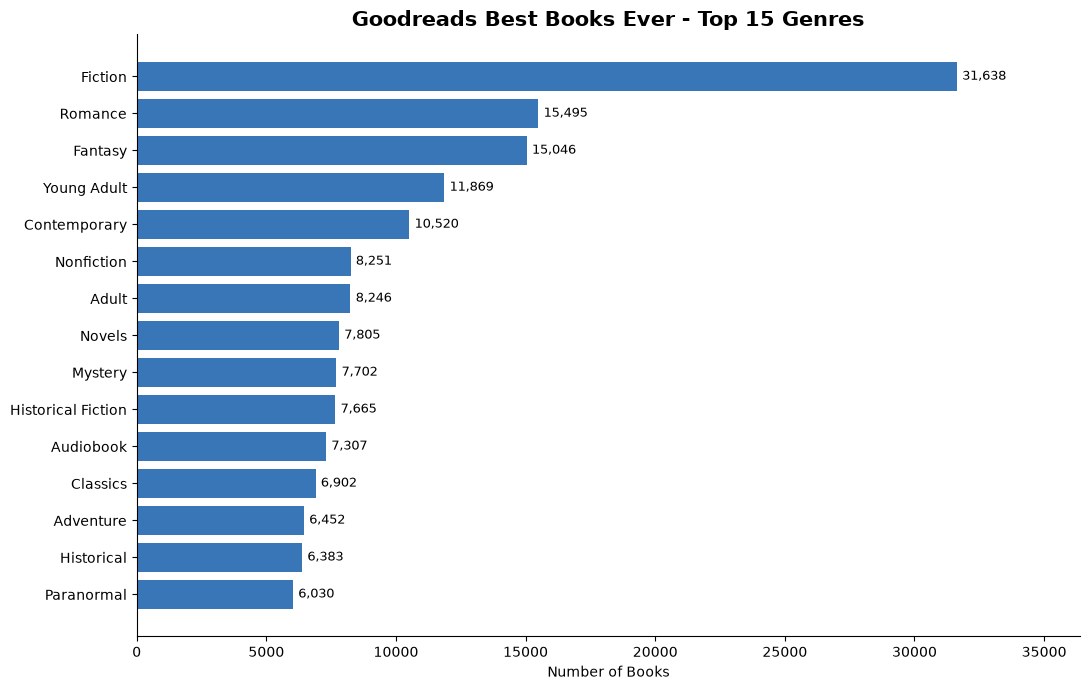

In [21]:
import matplotlib.pyplot as plt
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

# En yaygın 15 türü al
top_genres = genre_counts.most_common(15)

genres = [genre for genre, count in top_genres]
counts = [count for genre, count in top_genres]

fig, ax = plt.subplots(figsize=(11, 7))

bars = ax.barh(
    genres[::-1],
    counts[::-1],
    color="#3976B8"
)

for bar in bars:
    ax.text(
        bar.get_width() + 200,
        bar.get_y() + bar.get_height() / 2,
        f"{int(bar.get_width()):,}",
        va="center",
        fontsize=9
    )

ax.set_xlim(0, max(counts) * 1.15)
ax.set_xlabel("Number of Books")
ax.set_title(
    "Goodreads Best Books Ever - Top 15 Genres",
    fontsize=15,
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "goodreads_genre_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Kapak Görseli URL Kullanılabilirliği / Cover Image URL Availability

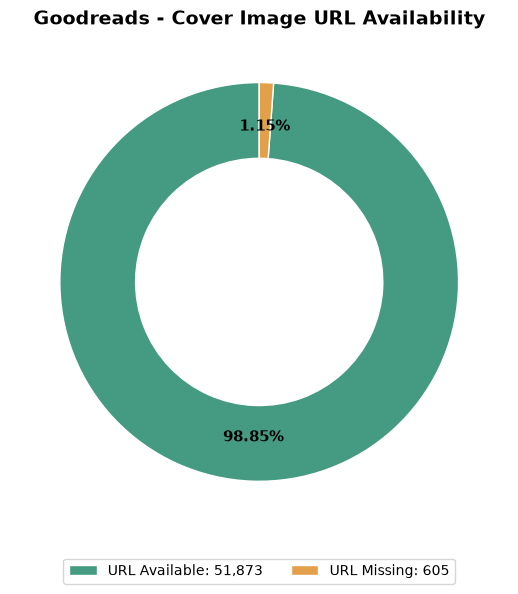

In [22]:
total_books = len(goodreads_df)

available = goodreads_df["coverImg"].notna().sum()
missing = total_books - available

values = [available, missing]
labels = ["URL Available", "URL Missing"]
colors = ["#459B81", "#E3A04B"]

fig, ax = plt.subplots(figsize=(8, 6))

wedges, _, autotexts = ax.pie(
    values,
    colors=colors,
    startangle=90,
    autopct="%1.2f%%",
    pctdistance=0.78,
    wedgeprops={"width": 0.38, "edgecolor": "white"}
)

for text in autotexts:
    text.set_fontsize(11)
    text.set_fontweight("bold")

ax.legend(
    wedges,
    [f"{label}: {value:,}" for label, value in zip(labels, values)],
    loc="lower center",
    bbox_to_anchor=(0.5, -0.12),
    ncol=2
)

ax.set_title(
    "Goodreads - Cover Image URL Availability",
    fontsize=14,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "goodreads_cover_url_availability.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

In [23]:
""" URL bulunması, görselin gerçekten indirilebilir olduğunu garanti etmez. İndirme başarısını daha sonra ayrıca ölçeceğiz. """

' URL bulunması, görselin gerçekten indirilebilir olduğunu garanti etmez. İndirme başarısını daha sonra ayrıca ölçeceğiz. '

## Eksik metadata analizi /  Missing Metadata Visualization

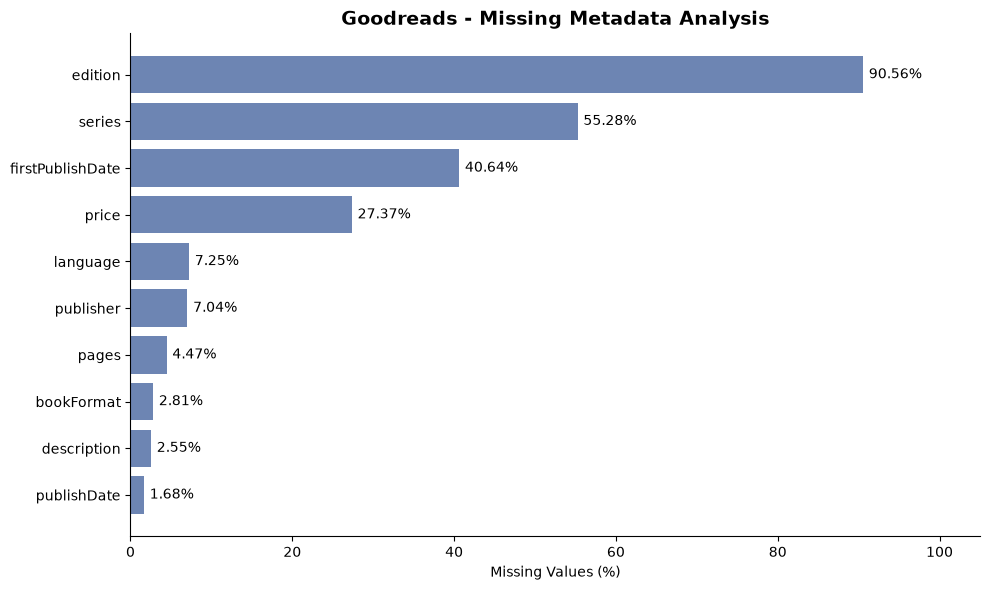

In [24]:
missing_percent = (
    goodreads_df.isna().mean() * 100
).sort_values(ascending=False)

# Eksik değeri bulunan ilk 10 sütun
top_missing = missing_percent[
    missing_percent > 0
].head(10)

fig, ax = plt.subplots(figsize=(10, 6))

bars = ax.barh(
    top_missing.index[::-1],
    top_missing.values[::-1],
    color="#6D85B3"
)

for bar in bars:
    ax.text(
        bar.get_width() + 0.7,
        bar.get_y() + bar.get_height() / 2,
        f"{bar.get_width():.2f}%",
        va="center",
        fontsize=10
    )

ax.set_xlim(0, 105)
ax.set_xlabel("Missing Values (%)")
ax.set_title(
    "Goodreads - Missing Metadata Analysis",
    fontsize=14,
    fontweight="bold"
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "goodreads_missing_values.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

## Goodreads ile BookCover30 Kategori Eşleştirme Analizi / Goodreads to BookCover30 Category Mapping Analysis

Goodreads tür etiketleri ile BookCover30 kategorileri arasındaki eşleşmeler incelenmektedir. Amaç, görsel sınıflandırma için kullanılabilecek kayıtları belirlemek ve birden fazla kategoriye karşılık gelen kitapları tespit etmektir.

In [25]:
# Goodreads türlerini BookCover30 sınıflarıyla eşleştirme

genre_to_label = {
    "Romance": 22,
    "Fantasy": 24,
    "Science Fiction": 24,
    "Mystery": 17,
    "Thriller": 17,
    "Young Adult": 27
}

label_names = {
    17: "Mystery, Thriller & Suspense",
    22: "Romance",
    24: "Science Fiction & Fantasy",
    27: "Teen & Young Adult"
}

# Bir kitabın eşleştiği farklı sınıfları bul
def get_candidate_labels(genres):
    return sorted({
        genre_to_label[genre]
        for genre in genres
        if genre in genre_to_label
    })

# Tür listesi ve kapak URL'si uygun kayıtlar
candidate_df = goodreads_df.loc[usable_records].copy()

candidate_df["candidate_labels"] = (
    candidate_df["genre_list"].apply(get_candidate_labels)
)

candidate_df["candidate_count"] = (
    candidate_df["candidate_labels"].apply(len)
)

print("Toplam aday kayıt:", len(candidate_df))

print(
    "Eşleşen kategori bulunamayan:",
    (candidate_df["candidate_count"] == 0).sum()
)

print(
    "Tek kategoriyle eşleşen:",
    (candidate_df["candidate_count"] == 1).sum()
)

print(
    "Birden fazla kategoriyle eşleşen:",
    (candidate_df["candidate_count"] > 1).sum()
)

print("\nTek kategoriyle eşleşen kitapların dağılımı:")

for label, name in label_names.items():

    count = candidate_df["candidate_labels"].apply(
        lambda labels: labels == [label]
    ).sum()

    print(f"{name}: {count}")

print("\nÖrnek eşleşmeler:")

display(
    candidate_df[
        candidate_df["candidate_count"] == 1
    ][
        ["title", "genres", "candidate_labels"]
    ].head(10)
)

Toplam aday kayıt: 47571
Eşleşen kategori bulunamayan: 16674
Tek kategoriyle eşleşen: 15367
Birden fazla kategoriyle eşleşen: 15530

Tek kategoriyle eşleşen kitapların dağılımı:
Mystery, Thriller & Suspense: 3418
Romance: 5587
Science Fiction & Fantasy: 4698
Teen & Young Adult: 1664

Örnek eşleşmeler:


,title,genres,candidate_labels
2,To Kill a Mockingbird,"['Classics', 'Fiction', 'Historical Fiction', ...",[27]
3,Pride and Prejudice,"['Classics', 'Fiction', 'Romance', 'Historical...",[22]
5,The Book Thief,"['Historical Fiction', 'Fiction', 'Young Adult...",[27]
6,Animal Farm,"['Classics', 'Fiction', 'Dystopia', 'Fantasy',...",[24]
9,Gone with the Wind,"['Classics', 'Historical Fiction', 'Fiction', ...",[22]
11,The Hitchhiker's Guide to the Galaxy,"['Science Fiction', 'Fiction', 'Humor', 'Fanta...",[24]
13,Wuthering Heights,"['Classics', 'Fiction', 'Romance', 'Gothic', '...",[22]
14,The Da Vinci Code,"['Fiction', 'Mystery', 'Thriller', 'Suspense',...",[17]
15,Memoirs of a Geisha,"['Fiction', 'Historical Fiction', 'Romance', '...",[22]
16,The Picture of Dorian Gray,"['Classics', 'Fiction', 'Horror', 'Fantasy', '...",[24]


## Kategori Eşleştirme Kalite İncelemesi / Category Mapping Quality Review

Bu bölümde tek kategoriyle eşleşen Goodreads kayıtlarından örnekler seçilerek kategori eşleştirmelerinin güvenilirliği incelenmekte

In [26]:
# Tek kategoriyle eşleşen kitapları seç
single_candidates = candidate_df[
    candidate_df["candidate_count"] == 1
].copy()

# Sayısal etiketi ayrı sütuna çıkar
single_candidates["proposed_label"] = (
    single_candidates["candidate_labels"].str[0]
)

# Her kategoriden 10 rastgele kitap incele
for label, category_name in label_names.items():

    category_books = single_candidates[
        single_candidates["proposed_label"] == label
    ]

    samples = category_books.sample(
        n=min(10, len(category_books)),
        random_state=42
    )

    print(f"\nKategori: {category_name}")
    print(f"Toplam aday: {len(category_books)}")

    display(
        samples[
            ["title", "genre_list", "proposed_label"]
        ]
    )


Kategori: Mystery, Thriller & Suspense
Toplam aday: 3418


,title,genre_list,proposed_label
29950,The Lie,"[Thriller, Mystery, Fiction, Crime, Suspense, ...",17
49238,Thursday the Rabbi Walked Out,"[Mystery, Fiction, Jewish, Judaism, Mystery Th...",17
2219,I Am Pilgrim,"[Thriller, Fiction, Mystery, Crime, Mystery Th...",17
8989,Mygale,"[Horror, Thriller, Fiction, France, Crime, Mys...",17
44084,Ratcatcher,"[Historical Fiction, Mystery, Historical, Fict...",17
26654,A Game of Greed and Deception,"[Mystery, Mystery Thriller, Suspense, Crime]",17
49432,Hickory Dickory Dock,"[Mystery, Fiction, Crime, Classics, Detective,...",17
26682,"Déjà Dead / Death du Jour (Temperance Brennan,...","[Mystery, Crime, Fiction, Thriller, Detective]",17
43821,The Old Silent,"[Mystery, Fiction, Crime, British Literature, ...",17
32644,Reina roja,"[Thriller, Spanish Literature, Fiction, Crime,...",17



Kategori: Romance
Toplam aday: 5587


,title,genre_list,proposed_label
40134,Faking Mr. Right,"[Romance, Contemporary Romance, Contemporary, ...",22
30848,Baby Jane,"[Fiction, LGBT, Finnish Literature, Contempora...",22
860,The Wedding,"[Romance, Fiction, Chick Lit, Contemporary, Ad...",22
1915,Ask the Dust,"[Fiction, Classics, Novels, American, Literatu...",22
5181,Rock the Heart,"[Romance, New Adult, Music, Contemporary Roman...",22
8278,Suddenly You,"[Historical Romance, Romance, Historical, Hist...",22
13054,"سيمون دو بوفوار وجان بول سارتر وجهاً لوجه ""الح...","[Biography, Nonfiction, Philosophy, History, F...",22
46425,A Texan's Luck,"[Historical Romance, Westerns, Romance, Histor...",22
40975,Remembered,"[Christian Fiction, Historical Fiction, Romanc...",22
3500,Seduction and Snacks,"[Romance, Humor, Contemporary, Contemporary Ro...",22



Kategori: Science Fiction & Fantasy
Toplam aday: 4698


,title,genre_list,proposed_label
39732,The Illumination,"[Fiction, Fantasy, Magical Realism, Contempora...",24
15196,Requiem: The Fall of the Templars,"[Historical Fiction, Historical, Fiction, Medi...",24
2899,A Song of Ice and Fire,"[Fantasy, Fiction, Epic Fantasy, Adventure, Sc...",24
6231,Princeps' Fury,"[Fantasy, Fiction, Epic Fantasy, High Fantasy,...",24
43775,Bloodstone,"[Fantasy, Fiction, Post Apocalyptic, Science F...",24
12030,What is Not Yours is Not Yours,"[Short Stories, Fiction, Magical Realism, Fant...",24
49220,Der Herr der Ringe. Anhänge und Register,"[Fantasy, Fiction, Classics, German Literature...",24
28388,2586 Kroków,"[Fantasy, Polish Literature, Fiction, Science ...",24
38097,Cugel Saga,"[Fantasy, Science Fiction, Fiction, Dying Eart...",24
32817,Inkheart Movie Novelization,"[Childrens, Fantasy]",24



Kategori: Teen & Young Adult
Toplam aday: 1664


,title,genre_list,proposed_label
46537,Ett öga rött,"[Fiction, Swedish Literature, Contemporary, Yo...",27
5232,Homeless Bird,"[Young Adult, Historical Fiction, Fiction, Ind...",27
7061,Rules,"[Realistic Fiction, Young Adult, Fiction, Midd...",27
52058,Histoires inédites du Petit Nicolas Volume 2 N...,"[Childrens, Fiction, France, Humor, Short Stor...",27
10101,Stone Fox,"[Fiction, Historical Fiction, Childrens, Anima...",27
8462,Skinny,"[Young Adult, Fiction, Mental Illness, Mental ...",27
50527,Elsie's Endless Wait,"[Historical Fiction, Christian Fiction, Christ...",27
40258,Last Term at Malory Towers,"[Childrens, Fiction, Classics, School Stories,...",27
51062,A Horse Called Hero,"[Historical Fiction, Horses, Animals, Historic...",27
15496,A Complicated Kindness,"[Fiction, Canada, Contemporary, Coming Of Age,...",27


## Harici Değerlendirme Veri Seti Hazırlığı /  External Evaluation Dataset Preparation

Bu bölümde Goodreads veri setindeki kitaplar BookCover30 kategorileriyle eşleştirilerek dış değerlendirme için aday kayıtlar hazırlanmaktadır.

Etiket belirsizliğini azaltmak amacıyla birden fazla kategoriyle eşleşen kayıtlar, Teen & Young Adult kategorisi ve bazı çakışan tür etiketleri ilk aşamada değerlendirme dışında bırakılmıştır.

In [27]:
# İlk aşamada kullanılacak kategoriler
selected_labels = {
    17: "Mystery, Thriller & Suspense",
    22: "Romance",
    24: "Science Fiction & Fantasy"
}

# Başka bir kategoriye işaret edebilecek türler
excluded_genres = {
    "Children's",
    "Middle Grade",
    "Picture Books",
    "Graphic Novels",
    "Comics",
    "Manga"
}

# Tek kategoriye eşleşen kitaplar
filtered_df = candidate_df[
    candidate_df["candidate_count"] == 1
].copy()

filtered_df["label"] = (
    filtered_df["candidate_labels"].str[0]
)

# Seçilen üç kategori
filtered_df = filtered_df[
    filtered_df["label"].isin(selected_labels)
].copy()

# Çakışabilecek türleri ele
filtered_df = filtered_df[
    ~filtered_df["genre_list"].apply(
        lambda genres: bool(set(genres) & excluded_genres)
    )
].copy()

# Tekrarlanan kayıtları kaldır
filtered_df = filtered_df.drop_duplicates(
    subset="bookId",
    keep="first"
)

filtered_df = filtered_df.drop_duplicates(
    subset="coverImg",
    keep="first"
)

# Kategori adlarını ekle
filtered_df["category"] = (
    filtered_df["label"].map(selected_labels)
)

# Orijinal CSV satır numarasıyla benzersiz dosya adı
filtered_df = filtered_df.copy()

filtered_df["filename"] = [
    f"goodreads_{idx:06d}.jpg"
    for idx in filtered_df.index
]

# İndirilecek kayıt listesi
download_manifest = filtered_df[
    ["bookId", "title", "coverImg",
     "filename", "label", "category"]
].copy()

# Listeyi kaydet
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

manifest_path = (
    PROCESSED_DIR / "goodreads_download_manifest.csv"
)

download_manifest.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)

print("İndirilecek aday kitap:", len(download_manifest))

print("\nKategori dağılımı:")
print(download_manifest["category"].value_counts())

print("\nListe kaydedildi:")
print(manifest_path)

display(download_manifest.head())

İndirilecek aday kitap: 12645

Kategori dağılımı:
category
Romance                         5494
Science Fiction & Fantasy       3825
Mystery, Thriller & Suspense    3326
Name: count, dtype: int64

Liste kaydedildi:
c:\Users\amine\Projects\book-cover-classification-bookstat\data\processed\goodreads_download_manifest.csv


,bookId,title,coverImg,filename,label,category
3,1885.Pride_and_Prejudice,Pride and Prejudice,https://i.gr-assets.com/images/S/compressed.ph...,goodreads_000003.jpg,22,Romance
6,170448.Animal_Farm,Animal Farm,https://i.gr-assets.com/images/S/compressed.ph...,goodreads_000006.jpg,24,Science Fiction & Fantasy
9,18405.Gone_with_the_Wind,Gone with the Wind,https://i.gr-assets.com/images/S/compressed.ph...,goodreads_000009.jpg,22,Romance
11,386162.The_Hitchhiker_s_Guide_to_the_Galaxy,The Hitchhiker's Guide to the Galaxy,https://i.gr-assets.com/images/S/compressed.ph...,goodreads_000011.jpg,24,Science Fiction & Fantasy
13,6185.Wuthering_Heights,Wuthering Heights,https://i.gr-assets.com/images/S/compressed.ph...,goodreads_000013.jpg,22,Romance


## Goodreads Kapaklarını İndirme Hazırlığı / Goodreads Cover Download Preparation

In [28]:
# Bütün geçerli kapak URL'lerini seç
valid_urls = (
    goodreads_df["coverImg"]
    .fillna("")
    .str.strip()
    .str.startswith(("http://", "https://"))
)

all_covers_df = goodreads_df.loc[
    valid_urls,
    ["bookId", "title", "coverImg", "genres"]
].copy()

# Her kayıt için benzersiz dosya adı
all_covers_df["filename"] = [
    f"goodreads_{idx:06d}.jpg"
    for idx in all_covers_df.index
]

# Tam indirme listesini kaydet
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

full_manifest_path = (
    PROCESSED_DIR / "goodreads_all_download_manifest.csv"
)

all_covers_df.to_csv(
    full_manifest_path,
    index=False,
    encoding="utf-8-sig"
)

print("Toplam Goodreads kaydı:", len(goodreads_df))
print("İndirilmeye aday kapak:", len(all_covers_df))
print("Liste:", full_manifest_path)

Toplam Goodreads kaydı: 52478
İndirilmeye aday kapak: 51873
Liste: c:\Users\amine\Projects\book-cover-classification-bookstat\data\processed\goodreads_all_download_manifest.csv


## İndirilen Kapak Görsellerinin Kalite Analizi / Downloaded Cover Images Quality Analysis

Bu bölümde indirilen Goodreads kapak görüntülerinin sayısı, boyutları, renk kanalları ve dosya bütünlüğü incelenmektedir.

In [29]:
from PIL import Image
from tqdm.auto import tqdm

IMAGE_DIR = PROJECT_ROOT / "data" / "goodreads_images"

MANIFEST_PATH = (
    PROJECT_ROOT
    / "data"
    / "processed"
    / "goodreads_all_download_manifest.csv"
)

manifest = pd.read_csv(MANIFEST_PATH)

image_files = sorted(IMAGE_DIR.glob("*.jpg"))

print("Manifest kayıt sayısı:", len(manifest))
print("Bulunan JPG dosyası:", len(image_files))

# Beklenen ve bulunan dosyaları karşılaştır
expected_files = set(manifest["filename"].astype(str))
actual_files = {path.name for path in image_files}

missing_files = expected_files - actual_files

print("İndirilemeyen dosya sayısı:", len(missing_files))
print("İndirilemeyen dosyalar:", sorted(missing_files))

# Görüntü özelliklerini incele
dimensions = Counter()
color_modes = Counter()
image_formats = Counter()
corrupt_files = []

for path in tqdm(image_files, desc="Görsel kalite kontrolü"):
    try:
        with Image.open(path) as img:
            dimensions[img.size] += 1
            color_modes[img.mode] += 1
            image_formats[img.format] += 1

            img.verify()

    except Exception as error:
        corrupt_files.append((path.name, str(error)))

print("\nEn yaygın görüntü boyutları:")
print(dimensions.most_common(10))

print("\nRenk modları:")
print(color_modes)

print("\nGörüntü formatları:")
print(image_formats)

print("\nBozuk / okunamayan dosya sayısı:", len(corrupt_files))

Manifest kayıt sayısı: 51873
Bulunan JPG dosyası: 51870
İndirilemeyen dosya sayısı: 3
İndirilemeyen dosyalar: ['goodreads_019295.jpg', 'goodreads_033125.jpg', 'goodreads_043831.jpg']


Görsel kalite kontrolü:   0%|          | 0/51870 [00:00<?, ?it/s]


En yaygın görüntü boyutları:
[((317, 475), 3232), ((316, 475), 2411), ((314, 475), 2303), ((315, 475), 1369), ((297, 475), 1268), ((313, 475), 1129), ((312, 475), 1117), ((308, 475), 1083), ((307, 475), 1047), ((295, 475), 999)]

Renk modları:
Counter({'RGB': 51870})

Görüntü formatları:
Counter({'JPEG': 51870})

Bozuk / okunamayan dosya sayısı: 0


## İndirilen Goodreads Kapak Örnekleri / Downloaded Goodreads Cover Samples

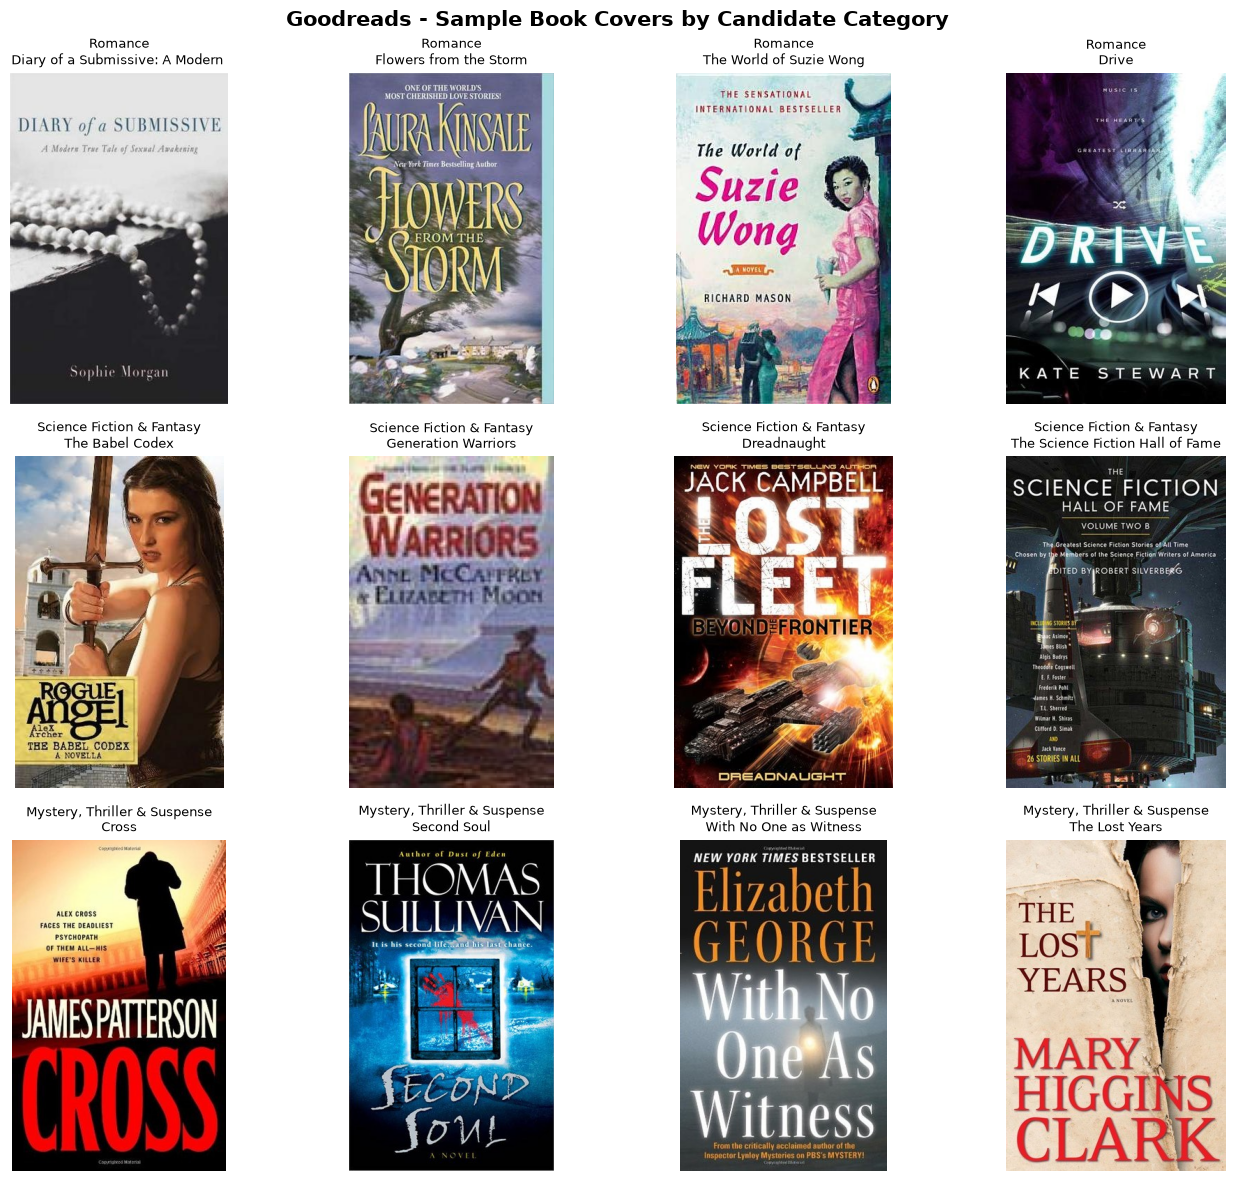

In [30]:
IMAGE_DIR = PROJECT_ROOT / "data" / "goodreads_images"
REPORTS_DIR = PROJECT_ROOT / "reports"

manifest = pd.read_csv(
    PROJECT_ROOT / "data" / "processed"
    / "goodreads_download_manifest.csv"
)

# Başarıyla indirilen kayıtları seç
available = manifest[
    manifest["filename"].apply(
        lambda name: (IMAGE_DIR / name).is_file()
    )
].copy()

categories = [
    "Romance",
    "Science Fiction & Fantasy",
    "Mystery, Thriller & Suspense"
]

fig, axes = plt.subplots(3, 4, figsize=(14, 12))

for i, category in enumerate(categories):

    samples = available[
        available["category"] == category
    ].sample(n=4, random_state=42)

    for j, (_, row) in enumerate(samples.iterrows()):

        image_path = IMAGE_DIR / row["filename"]

        with Image.open(image_path) as img:
            axes[i, j].imshow(img.convert("RGB"))

        axes[i, j].set_title(
            f"{category}\n{str(row['title'])[:32]}",
            fontsize=9
        )

        axes[i, j].axis("off")

plt.suptitle(
    "Goodreads - Sample Book Covers by Candidate Category",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    REPORTS_DIR / "goodreads_sample_covers.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()